In [1]:
import pandas as pd, numpy as np, re, glob
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
RS = 42

In [2]:
!pip -q install gdown
!gdown --folder "https://drive.google.com/drive/folders/1Qq4NnMbpXhBOOZp84Hh6fRZ2Hcd5aHe8?usp=sharing" -O /content/data

file = glob.glob('/content/**/sanjeevani_diabetes_screening_raw.csv', recursive=True)[0]
print(file)

Retrieving folder contents
Processing file 1nQhMfLtx4JT8739nEOt0bt7t5FSH1gb9 dashmart_delivery_times_raw.csv
Processing file 1D_YdBTIfGl6C4W__yjOWclpBlSdKxD3A sanjeevani_diabetes_screening_raw.csv
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1nQhMfLtx4JT8739nEOt0bt7t5FSH1gb9
To: /content/data/dashmart_delivery_times_raw.csv
100% 135k/135k [00:00<00:00, 40.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1D_YdBTIfGl6C4W__yjOWclpBlSdKxD3A
To: /content/data/sanjeevani_diabetes_screening_raw.csv
100% 219k/219k [00:00<00:00, 82.4MB/s]
Download completed
/content/data/sanjeevani_diabetes_screening_raw.csv


### Q1

In [3]:
raw = pd.read_csv(file, dtype=str, keep_default_na=False)
print('shape:', raw.shape)
print('raw column names:', [repr(c) for c in raw.columns])

def find(col):
    return [c for c in raw.columns if c.strip().lower() == col.lower()][0]

for c in ['Sex', 'family_history', 'HbA1c Result']:
    real = find(c)
    print(f'\n{repr(real)} ->', sorted(raw[real].unique()))

print('\nInterpretation: the target and Sex are written in many different ways, and the target column name has a trailing space.')

shape: (3038, 13)
raw column names: ["'Patient ID'", "'Camp Location'", "'Sex'", "'Age'", "'family_history'", "'height_cm'", "'weight_kg'", "'BMI'", "'waist_cm'", "'Daily Steps'", "'Blood Pressure'", "'total_cholesterol'", "'HbA1c Result '"]

'Sex' -> ['F', 'FEMALE', 'Female', 'M', 'MALE', 'Male', 'female', 'male']

'family_history' -> ['0', '1', 'N', 'No', 'Y', 'Yes', 'no', 'yes']

'HbA1c Result ' -> ['0', '1', 'DIABETIC', 'Negative', 'No', 'Positive', 'Yes', 'normal']

Interpretation: the target and Sex are written in many different ways, and the target column name has a trailing space.


### Q2

In [4]:
df = raw.copy()
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r'[^a-z0-9]+', '_', regex=True).str.strip('_'))
print(df.columns.tolist())

df = df.apply(lambda s: s.str.strip())
df = df.replace(r'(?i)^(na|n/a|\?|not measured|nan|none|)$', np.nan, regex=True)

df['camp_location'] = df['camp_location'].str.replace(r'\s+', ' ', regex=True).str.title()
df['sex'] = df['sex'].str.lower().str[0].map({'m': 'Male', 'f': 'Female'})

print(df['camp_location'].value_counts(dropna=False))
print(df['sex'].value_counts(dropna=False))
print('Interpretation: each location and sex now has exactly one spelling.')

['patient_id', 'camp_location', 'sex', 'age', 'family_history', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'daily_steps', 'blood_pressure', 'total_cholesterol', 'hba1c_result']
camp_location
Panvel      554
Kharghar    522
Dombivli    500
Vashi       498
Nerul       491
Thane       473
Name: count, dtype: int64
sex
Female    1521
Male      1517
Name: count, dtype: int64
Interpretation: each location and sex now has exactly one spelling.


### Q3

In [5]:
df['family_history'] = df['family_history'].str.lower().map(
    {'yes': 1, 'y': 1, '1': 1, 'no': 0, 'n': 0, '0': 0})
df['hba1c_result'] = df['hba1c_result'].str.lower().map(
    {'positive': 1, 'yes': 1, '1': 1, 'diabetic': 1,
     'negative': 0, 'no': 0, '0': 0, 'normal': 0})
print('unmapped target values:', df['hba1c_result'].isna().sum())
print(f"share positive: {df['hba1c_result'].mean():.3f}")

print('rows before dedupe:', len(df))
print('exact duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('rows after dedupe:', len(df))
print(f"Interpretation: about {df['hba1c_result'].mean():.0%} of visitors are diabetic, which is the hit-rate a random pick would get.")

unmapped target values: 0
share positive: 0.225
rows before dedupe: 3038
exact duplicate rows: 38
rows after dedupe: 3000
Interpretation: about 23% of visitors are diabetic, which is the hit-rate a random pick would get.


### Q4

In [6]:
bp = df['blood_pressure'].str.extract(r'(\d+)\s*/\s*(\d+)')
df['systolic'] = pd.to_numeric(bp[0])
df['diastolic'] = pd.to_numeric(bp[1])

df['daily_steps'] = df['daily_steps'].str.replace(',', '', regex=False)
num_cols = ['age', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'daily_steps', 'total_cholesterol']
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')

print(df[['blood_pressure', 'systolic', 'diastolic', 'daily_steps']].head())
print(df.dtypes)
print('Interpretation: all measurements are numeric now; blood pressure became two usable columns.')

  blood_pressure  systolic  diastolic  daily_steps
0         102/69     102.0       69.0       8750.0
1         106/73     106.0       73.0      12930.0
2         136/98     136.0       98.0       6440.0
3         114/90     114.0       90.0       4080.0
4         124/89     124.0       89.0       4890.0
patient_id            object
camp_location         object
sex                   object
age                    int64
family_history         int64
height_cm            float64
weight_kg            float64
bmi                  float64
waist_cm             float64
daily_steps          float64
blood_pressure        object
total_cholesterol    float64
hba1c_result           int64
systolic             float64
diastolic            float64
dtype: object
Interpretation: all measurements are numeric now; blood pressure became two usable columns.


### Q5

In [7]:
in_metres = df['height_cm'] < 3
print('heights typed in metres:', in_metres.sum())
ex = df[in_metres].index[:3]
print('BEFORE'); display(df.loc[ex, ['height_cm', 'weight_kg', 'bmi']])
df.loc[in_metres, 'height_cm'] = df.loc[in_metres, 'height_cm'] * 100
print('AFTER'); display(df.loc[ex, ['height_cm', 'weight_kg', 'bmi']])

bmi_calc = df['weight_kg'] / (df['height_cm'] / 100) ** 2
blank = df['bmi'].isna()
print('blank BMI:', blank.sum())
ex2 = df[blank].index[:3]
print('BEFORE'); display(df.loc[ex2, ['height_cm', 'weight_kg', 'bmi']])
df.loc[blank, 'bmi'] = bmi_calc[blank]
print('AFTER'); display(df.loc[ex2, ['height_cm', 'weight_kg', 'bmi']])
print('blank BMI left:', df['bmi'].isna().sum())

heights typed in metres: 45
BEFORE


,height_cm,weight_kg,bmi
63,1.56,44.3,NaN
168,1.65,61.1,NaN
177,1.61,75.4,NaN


AFTER


,height_cm,weight_kg,bmi
63,156.0,44.3,NaN
168,165.0,61.1,NaN
177,161.0,75.4,NaN


blank BMI: 320
BEFORE


,height_cm,weight_kg,bmi
56,177.0,69.9,NaN
63,156.0,44.3,NaN
73,166.0,67.3,NaN


AFTER


,height_cm,weight_kg,bmi
56,177.0,69.9,22.311596
63,156.0,44.3,18.203485
73,166.0,67.3,24.422993


blank BMI left: 0


### Q6

In [8]:
bad_age = (df['age'] < 10) | (df['age'] > 100)
print('impossible ages:', sorted(df.loc[bad_age, 'age'].unique()))
df.loc[bad_age, 'age'] = np.nan

print(df.isna().sum())
df.to_csv('sanjeevani_clean.csv', index=False)
print('saved sanjeevani_clean.csv', df.shape)
print('Interpretation: only a few ages are missing; some other columns have gaps that need imputing later.')

impossible ages: [np.int64(0), np.int64(3), np.int64(140), np.int64(999)]
patient_id             0
camp_location          0
sex                    0
age                    7
family_history         0
height_cm              0
weight_kg              0
bmi                    0
waist_cm              90
daily_steps           60
blood_pressure        25
total_cholesterol    150
hba1c_result           0
systolic              25
diastolic             25
dtype: int64
saved sanjeevani_clean.csv (3000, 15)
Interpretation: only a few ages are missing; some other columns have gaps that need imputing later.


Imputation plan: SimpleImputer(strategy='median')for the numeric features and `most_frequent for sex and family_history, placed *inside* the Pipeline. The median is robust to outliers.

**Why not before the split?** The median would be calculated using test rows too, so information from the test set would leak into training and make the test score look better than it really is. Inside the pipeline the median is learned from the training rows only.

### Q7 - Raw Euclidean distance
New visitor: waist = 98, steps = 6000. Distance = sqrt((waist - 98)^2 + (steps - 6000)^2)

- P1: sqrt((76-98)^2 + (6050-6000)^2) = sqrt(484 + 2500) = sqrt(2984) = **54.63**
- P2: sqrt((80-98)^2 + (5980-6000)^2) = sqrt(324 + 400) = sqrt(724) = **26.91**
- P3: sqrt(3^2 + 1400^2) = sqrt(1,960,009) = **1400.00**
- P4: sqrt(2^2 + 2000^2) = sqrt(4,000,004) = **2000.00**
- P5: sqrt(8^2 + 1500^2) = sqrt(2,250,064) = **1500.02**
- P6: sqrt(16^2 + 100^2) = sqrt(10,256) = **101.27**

k = 3 nearest: **P2 (26.9), P1 (54.6), P6 (101.3)**, all Negative, so the prediction is **Negative**.

In [9]:
past = pd.DataFrame({'visitor': ['P1','P2','P3','P4','P5','P6'],
                     'waist': [76, 80, 101, 96, 106, 82],
                     'steps': [6050, 5980, 7400, 8000, 4500, 6100],
                     'result': ['Negative','Negative','Positive','Positive','Positive','Negative']})
new_w, new_s = 98, 6000
past['euclid_raw'] = np.sqrt((past.waist - new_w)**2 + (past.steps - new_s)**2)
print(past.sort_values('euclid_raw').round(2))
print('k=3 vote:', past.nsmallest(3, 'euclid_raw')['result'].value_counts().to_dict())

  visitor  waist  steps    result  euclid_raw
1      P2     80   5980  Negative       26.91
0      P1     76   6050  Negative       54.63
5      P6     82   6100  Negative      101.27
2      P3    101   7400  Positive     1400.00
4      P5    106   4500  Positive     1500.02
3      P4     96   8000  Positive     2000.00
k=3 vote: {'Negative': 3}


### Q8 - Min-max scaling (waist 60-140, steps 0-20,000)
Scaled value = (x - min) / (max - min). New visitor: waist = (98-60)/80 = 0.475, steps = 6000/20000 = 0.300

| Visitor | waist scaled | steps scaled | Euclidean |
|---|---|---|---|
| P1 | 0.2000 | 0.3025 | sqrt(0.275^2 + 0.0025^2) = **0.2750** |
| P2 | 0.2500 | 0.2990 | sqrt(0.225^2 + 0.001^2) = **0.2250** |
| P3 | 0.5125 | 0.3700 | sqrt(0.0375^2 + 0.07^2) = **0.0794** |
| P4 | 0.4500 | 0.4000 | sqrt(0.025^2 + 0.1^2) = **0.1031** |
| P5 | 0.5750 | 0.2250 | sqrt(0.1^2 + 0.075^2) = **0.1250** |
| P6 | 0.2750 | 0.3050 | sqrt(0.2^2 + 0.005^2) = **0.2001** |

k = 3 nearest: **P3, P4, P5**, all Positive, so the prediction is **Positive**.

**Why it flipped:** in raw units steps are in the thousands and waist in tens, so the step difference swamped the waist difference and "similar" really meant "similar steps". After scaling, both features count equally, and the new visitor's waist (98 cm) is very close to the high-waist diabetics. A doctor would agree with the scaled answer: a 98 cm waist is a well-known diabetes risk marker, while a 50-step difference is meaningless.

In [10]:
def mm(x, lo, hi): return (x - lo) / (hi - lo)
past['w_s'] = mm(past.waist, 60, 140); past['s_s'] = mm(past.steps, 0, 20000)
nw, ns = mm(new_w, 60, 140), mm(new_s, 0, 20000)
past['euclid_scaled'] = np.sqrt((past.w_s - nw)**2 + (past.s_s - ns)**2)
print(past[['visitor','w_s','s_s','euclid_scaled','result']].sort_values('euclid_scaled').round(4))
print('k=3 vote:', past.nsmallest(3, 'euclid_scaled')['result'].value_counts().to_dict())

  visitor     w_s     s_s  euclid_scaled    result
2      P3  0.5125  0.3700         0.0794  Positive
3      P4  0.4500  0.4000         0.1031  Positive
4      P5  0.5750  0.2250         0.1250  Positive
5      P6  0.2750  0.3050         0.2001  Negative
1      P2  0.2500  0.2990         0.2250  Negative
0      P1  0.2000  0.3025         0.2750  Negative
k=3 vote: {'Positive': 3}


### Q9 - Manhattan distance on scaled features
Manhattan = |dw| + |ds|

- P1: 0.2750 + 0.0025 = **0.2775**
- P2: 0.2250 + 0.0010 = **0.2260**
- P3: 0.0375 + 0.0700 = **0.1075**
- P4: 0.0250 + 0.1000 = **0.1250**
- P5: 0.1000 + 0.0750 = **0.1750**
- P6: 0.2000 + 0.0050 = **0.2050**

k = 3 nearest: P3, P4, P5 are all Positive, so the prediction is **unchanged (Positive)**.

**When to prefer Manhattan:** with many features (high dimensions), when there are outliers or a few large differences (it does not square them), or when features are count-like or grid-like and each feature should add up independently.

In [11]:
past['manhattan'] = (past.w_s - nw).abs() + (past.s_s - ns).abs()
print(past[['visitor','manhattan','result']].sort_values('manhattan').round(4))
print('k=3 vote:', past.nsmallest(3, 'manhattan')['result'].value_counts().to_dict())

  visitor  manhattan    result
2      P3     0.1075  Positive
3      P4     0.1250  Positive
4      P5     0.1750  Positive
5      P6     0.2050  Negative
1      P2     0.2260  Negative
0      P1     0.2775  Negative
k=3 vote: {'Positive': 3}


### Q10

In [12]:
num_feats = ['age', 'bmi', 'waist_cm', 'daily_steps', 'systolic', 'diastolic', 'total_cholesterol']
cat_feats = ['sex', 'family_history']

data = df.dropna(subset=['hba1c_result']).copy()
y = data['hba1c_result'].astype(int)
X = data[num_feats + cat_feats]

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RS)
y_arr = yte.values

print('train:', Xtr.shape, ' test:', Xte.shape)
print(f'positive rate - train: {ytr.mean():.3f}, test: {yte.mean():.3f}')
baseline_acc = 1 - yte.mean()
print(f'baseline accuracy (predict all negative): {baseline_acc:.3f}')
print(f'Interpretation: the split keeps the same positive rate, and a model that never finds a diabetic already scores about {baseline_acc:.0%} accuracy.')

train: (2250, 9)  test: (750, 9)
positive rate - train: 0.226, test: 0.227
baseline accuracy (predict all negative): 0.773
Interpretation: the split keeps the same positive rate, and a model that never finds a diabetic already scores about 77% accuracy.


### Q11

In [13]:
def evaluate(name, model, X_in):
    """one place to compute every metric so the tables match"""
    p = model.predict_proba(X_in)[:, 1]
    pred = (p >= 0.5).astype(int)
    top = np.argsort(-p, kind='stable')[:250]
    return {'model': name,
            'accuracy': accuracy_score(y_arr, pred),
            'precision': precision_score(y_arr, pred, zero_division=0),
            'recall': recall_score(y_arr, pred, zero_division=0),
            'f1': f1_score(y_arr, pred, zero_division=0),
            'roc_auc': roc_auc_score(y_arr, p),
            'found_in_top250': int(y_arr[top].sum())}

raw_knn = make_pipeline(SimpleImputer(strategy='median'), KNeighborsClassifier(n_neighbors=5))
raw_knn.fit(Xtr[num_feats], ytr)
res_raw = evaluate('Raw KNN (k=5)', raw_knn, Xte[num_feats])
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res_raw.items()})
print('confusion matrix [[TN, FP], [FN, TP]]:')
print(confusion_matrix(y_arr, (raw_knn.predict_proba(Xte[num_feats])[:, 1] >= 0.5).astype(int)))
print(f'Interpretation: accuracy {res_raw["accuracy"]:.3f} vs baseline {baseline_acc:.3f} - '
      f'barely different, and recall is only {res_raw["recall"]:.2f}, so the model hardly finds diabetics.')

{'model': 'Raw KNN (k=5)', 'accuracy': 0.763, 'precision': 0.441, 'recall': 0.176, 'f1': 0.252, 'roc_auc': np.float64(0.656), 'found_in_top250': 81}
confusion matrix [[TN, FP], [FN, TP]]:
[[542  38]
 [140  30]]
Interpretation: accuracy 0.763 vs baseline 0.773 - barely different, and recall is only 0.18, so the model hardly finds diabetics.


### Q12

In [14]:
scaled_knn = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                           KNeighborsClassifier(n_neighbors=5))
scaled_knn.fit(Xtr[num_feats], ytr)
res_scaled = evaluate('Scaled KNN (k=5)', scaled_knn, Xte[num_feats])

side = pd.DataFrame([res_raw, res_scaled]).set_index('model').drop(columns='found_in_top250')
display(side.round(3))

var = Xtr[num_feats].var()
print((var / var.sum()).round(4).sort_values(ascending=False))
print('Interpretation: daily_steps has by far the largest spread, so in raw KNN it dominates the distance and the other features barely count.')

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Raw KNN (k=5),0.763,0.441,0.176,0.252,0.656
Scaled KNN (k=5),0.788,0.552,0.341,0.422,0.722


daily_steps          0.9998
total_cholesterol    0.0001
age                  0.0000
waist_cm             0.0000
bmi                  0.0000
systolic             0.0000
diastolic            0.0000
dtype: float64
Interpretation: daily_steps has by far the largest spread, so in raw KNN it dominates the distance and the other features barely count.


### Q13

The scaler learns the mean and standard deviation from whatever it is fitted on. If it were fitted on the full data (or on the test set), the test rows would help set the scale used on the training rows, so the test set would no longer be "unseen" and our scores would be slightly optimistic (data leakage). Inside a `Pipeline`, `.fit(X_train)` fits the imputer and scaler on the training rows only, and `.predict(X_test)` only *applies* them. In cross-validation, the pipeline is re-fitted inside every fold.

In [15]:
pipe_demo = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsClassifier(5))
pipe_demo.fit(Xtr[num_feats], ytr)
pipe_demo.predict(Xte[num_feats])

print('scaler mean (steps):', pipe_demo.named_steps['standardscaler'].mean_[3].round(2))
print('train mean (steps) :', Xtr['daily_steps'].mean().round(2))
print('all-data mean      :', X['daily_steps'].mean().round(2))

scaler mean (steps): 6571.2
train mean (steps) : 6569.53
all-data mean      : 6545.93


### Q14

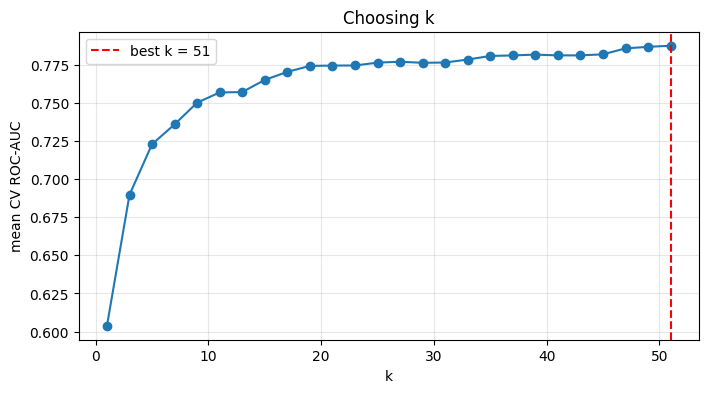

best k = 51, CV AUC = 0.7876
Interpretation: AUC rises quickly from k=1, peaks, and then slowly drifts down.


In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
ks = list(range(1, 52, 2))
cv_auc = []
for k in ks:
    p = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_auc.append(cross_val_score(p, Xtr[num_feats], ytr, cv=cv, scoring='roc_auc').mean())

best_k = ks[int(np.argmax(cv_auc))]
plt.figure(figsize=(8, 4))
plt.plot(ks, cv_auc, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'best k = {best_k}')
plt.xlabel('k'); plt.ylabel('mean CV ROC-AUC'); plt.title('Choosing k'); plt.legend(); plt.grid(alpha=.3)
plt.show()
print(f'best k = {best_k}, CV AUC = {max(cv_auc):.4f}')
print('Interpretation: AUC rises quickly from k=1, peaks, and then slowly drifts down.')

Very small k (e.g. 1): low bias but high variance. The model follows individual noisy patients, and one odd neighbour decides the answer, so the CV score is poor.
**Very large k:** high bias but low variance. The vote is taken over so many people that local patterns are averaged away and the model drifts towards "predict the majority class".
The best k sits in the middle of that bias-variance trade-off.

### Q15

In [17]:
prep = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_feats),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat_feats)])

pipe = Pipeline([('prep', prep), ('knn', KNeighborsClassifier())])
param_grid = {'knn__n_neighbors': list(range(1, 52, 2)),
              'knn__weights': ['uniform', 'distance'],
              'knn__p': [1, 2]}
gs = GridSearchCV(pipe, param_grid, scoring='roc_auc', cv=cv, n_jobs=-1)
gs.fit(Xtr, ytr)
print('best params:', gs.best_params_)
print(f'best CV ROC-AUC: {gs.best_score_:.4f}')
print(f'Interpretation: plain scaled model CV AUC at best k was {max(cv_auc):.4f}; tuned model with sex + family history is {gs.best_score_:.4f}.')

best params: {'knn__n_neighbors': 51, 'knn__p': 2, 'knn__weights': 'distance'}
best CV ROC-AUC: 0.7994
Interpretation: plain scaled model CV AUC at best k was 0.7876; tuned model with sex + family history is 0.7994.


### Q16

In [18]:
best = gs.best_estimator_
proba = best.predict_proba(Xte)[:, 1]
pred = (proba >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_arr, pred).ravel()
print('confusion matrix [[TN, FP], [FN, TP]]:\n', confusion_matrix(y_arr, pred))
print(f'accuracy {accuracy_score(y_arr, pred):.3f} | precision {precision_score(y_arr, pred):.3f} | '
      f'recall {recall_score(y_arr, pred):.3f} | F1 {f1_score(y_arr, pred):.3f} | ROC-AUC {roc_auc_score(y_arr, proba):.3f}')
print()
print(f'TP = {tp}: diabetics we correctly sent for the test.')
print(f'TN = {tn}: healthy people we correctly did not test.')
print(f'FP = {fp}: healthy people we tested by mistake (wasted Rs {fp*450}).')
print(f'FN = {fn}: diabetics we sent home without a test (the costly mistake).')
print('Interpretation: accuracy looks fine, but a large share of diabetics are missed (FN).')

confusion matrix [[TN, FP], [FN, TP]]:
 [[571   9]
 [139  31]]
accuracy 0.803 | precision 0.775 | recall 0.182 | F1 0.295 | ROC-AUC 0.805

TP = 31: diabetics we correctly sent for the test.
TN = 571: healthy people we correctly did not test.
FP = 9: healthy people we tested by mistake (wasted Rs 4050).
FN = 139: diabetics we sent home without a test (the costly mistake).
Interpretation: accuracy looks fine, but a large share of diabetics are missed (FN).


### Q17

**Why Camp Location was left out:** it is a label for *where* the camp ran, not a measurement of the person's health. KNN would treat it as a distance dimension, and encoding 6 locations as one-hot columns adds 6 extra dimensions that mostly add noise.

**For including it:** locations may differ in diet, lifestyle and income, so it could carry real signal that the body measurements miss.
**Against including it:** it can act as a proxy for community or income and be unfair; the model may learn the pilot's camp mix, and it will break when a new camp location opens.

### Q18

In [19]:
print(f'recall at 0.5 = {recall_score(y_arr, pred):.3f}  ->  {fn} of {y_arr.sum()} diabetics missed')

recall at 0.5 = 0.182  ->  139 of 170 diabetics missed


A 0.5 cut-off only flags someone when most of their neighbours are diabetic, which is a very strict rule when only ~22% of people are diabetic, so many diabetics are missed. Accuracy is highest there only because most people are negative. Missing a diabetic costs far more than testing a healthy person for Rs 450, so we should lower the cut-off or, better, rank people and spend the fixed budget on the highest-risk ones.

### Q19

In [20]:
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5]:
    sel = proba >= t
    tests = int(sel.sum())
    found = int(y_arr[sel].sum())
    rows.append({'threshold': t, 'tests_ordered': tests, 'diabetics_found': found,
                 'diabetics_missed': int(y_arr.sum() - found),
                 'hit_rate': found / tests if tests else np.nan,
                 'cost_per_diabetic_found_Rs': 450 * tests / found if found else np.nan})
thr_table = pd.DataFrame(rows)
display(thr_table.round(3))
print('Interpretation: lower thresholds find more diabetics but order many more tests; the budget allows only 250.')

,threshold,tests_ordered,diabetics_found,diabetics_missed,hit_rate,cost_per_diabetic_found_Rs
0,0.1,523,158,12,0.302,1489.557
1,0.2,332,135,35,0.407,1106.667
2,0.3,188,96,74,0.511,881.250
3,0.4,99,57,113,0.576,781.579
4,0.5,40,31,139,0.775,580.645


Interpretation: lower thresholds find more diabetics but order many more tests; the budget allows only 250.


### Q20

In [21]:
order = np.argsort(-proba, kind='stable')
top250 = order[:250]
found_top = int(y_arr[top250].sum())
total_pos = int(y_arr.sum())
random_expected = 250 * y_arr.mean()
print(f'top 250 found {found_top} diabetics out of {total_pos} total ({found_top/total_pos:.1%} of all diabetics)')
print(f'random choice would find about {random_expected:.0f}  ->  model finds {found_top/random_expected:.2f}x as many')
print(f'probability at the 250th place: {proba[order[249]]:.3f}; people tied at that value: {(proba == proba[order[249]]).sum()}')
print('Interpretation: ranking by probability beats random picking by a wide margin.')

top 250 found 117 diabetics out of 170 total (68.8% of all diabetics)
random choice would find about 57  ->  model finds 2.06x as many
probability at the 250th place: 0.258; people tied at that value: 1
Interpretation: ranking by probability beats random picking by a wide margin.


### Q21

In [22]:
info = data.loc[Xte.index]
rule = (info['age'] >= 45) & (((info['sex'] == 'Male') & (info['waist_cm'] >= 90)) |
                              ((info['sex'] == 'Female') & (info['waist_cm'] >= 80)))
rule = rule.values
rule_tests = int(rule.sum()); rule_found = int(y_arr[rule].sum())
print(f'eyeball rule: {rule_tests} tests, {rule_found} diabetics found, hit-rate {rule_found/rule_tests:.3f}')
print(f'KNN top 250 : 250 tests, {found_top} diabetics found, hit-rate {found_top/250:.3f}')
print(f'diabetics per Rs 10,000 - rule: {rule_found/(rule_tests*450)*10000:.2f}, KNN: {found_top/(250*450)*10000:.2f}')
print('Interpretation: compare the hit-rates above - the higher one gets more diabetics for every rupee spent.')

eyeball rule: 350 tests, 118 diabetics found, hit-rate 0.337
KNN top 250 : 250 tests, 117 diabetics found, hit-rate 0.468
diabetics per Rs 10,000 - rule: 7.49, KNN: 10.40
Interpretation: compare the hit-rates above - the higher one gets more diabetics for every rupee spent.


### Q22

In [23]:
prep_fit = best.named_steps['prep']
knn_fit = best.named_steps['knn']
i = order[0]
person = Xte.iloc[[i]]
xt_one = prep_fit.transform(person)
k_used = knn_fit.n_neighbors
dist, idx = knn_fit.kneighbors(xt_one, n_neighbors=k_used)

print('Visitor:'); display(person.round(1))
nb = Xtr.iloc[idx[0][:5]][['age', 'bmi', 'waist_cm', 'daily_steps', 'sex', 'family_history']].copy()
nb['hba1c'] = ytr.iloc[idx[0][:5]].values
nb['distance'] = dist[0][:5]
print('5 closest past visitors:'); display(nb.round(2))

pos_nb = int(ytr.iloc[idx[0]].sum())
print(f'Volunteer script: "Out of the {k_used} past visitors most like you in age, weight, waist and activity, '
      f'{pos_nb} turned out to have diabetes. That is much higher than the usual {ytr.mean():.0%}, '
      f'so you are one of the people we should test first."')

Visitor:


,age,bmi,waist_cm,daily_steps,systolic,diastolic,total_cholesterol,sex,family_history
2960,63.0,35.3,102.0,4300.0,152.0,97.0,223.0,Male,1


5 closest past visitors:


,age,bmi,waist_cm,daily_steps,sex,family_history,hba1c,distance
2247,56.0,34.00,101.0,4460.0,Female,1,0,1.74
1003,70.0,34.25,105.0,8360.0,Female,1,1,2.26
214,60.0,27.55,99.0,5420.0,Male,1,0,2.28
2529,49.0,32.20,102.0,5640.0,Male,1,0,2.32
2497,59.0,28.70,103.0,3790.0,Male,0,1,2.33


Volunteer script: "Out of the 51 past visitors most like you in age, weight, waist and activity, 39 turned out to have diabetes. That is much higher than the usual 23%, so you are one of the people we should test first."


### Q23

**Reply to the visitor ranked 260th:**
"We are sorry - this is not about your friend being treated better. We only have money for 250 tests out of 750 people, so the computer ranks everybody by how similar they are to past diabetic patients and we test from the top. Weight is only one of the things it compares: it also looks at age, waist, blood pressure, cholesterol, daily steps and family history, all together. Your friend may have looked more like earlier patients on the whole, even with the same weight. The difference between 250th and 260th place is tiny, so please do not read it as 'you are healthy' - if you have symptoms or a family history, please visit your doctor or a lab for a test."

### Q24

In [24]:
res_tuned = evaluate('Tuned KNN (grid search)', best, Xte)
summary = pd.DataFrame([res_raw, res_scaled, res_tuned]).set_index('model')
summary = summary[['accuracy', 'recall', 'roc_auc', 'found_in_top250']]
summary.columns = ['accuracy', 'recall_at_0.5', 'roc_auc', 'diabetics_found_in_top250']
display(summary.round(3))
print('Interpretation: scaling is the big jump; tuning adds a smaller gain, and the ranking (AUC / top-250) matters more than accuracy.')

,accuracy,recall_at_0.5,roc_auc,diabetics_found_in_top250
model,,,,
Raw KNN (k=5),0.763,0.176,0.656,81
Scaled KNN (k=5),0.788,0.341,0.722,99
Tuned KNN (grid search),0.803,0.182,0.805,117


Interpretation: scaling is the big jump; tuning adds a smaller gain, and the ranking (AUC / top-250) matters more than accuracy.


### Q25

In [25]:
rule_per_250 = 250 * rule_found / rule_tests
gain = found_top - rule_per_250
print(f"""RECOMMENDATION
Sanjeevani should use this tuned KNN model to rank visitors, because on the test set its top 250 picks found {found_top} of {total_pos} diabetics against about {random_expected:.0f} for random picking. On the day, volunteers enter the free measurements into the tablet, the model gives each visitor a risk probability, and the day's 250 highest-ranked people (one third of the camp) get the Rs 450 HbA1c test. Today's age-and-waist rule would find about {rule_per_250:.0f} diabetics per 250 tests, so the model finds roughly {gain:.0f} more diabetics for the same budget. The model should help the volunteers, not replace them, so anyone with symptoms should still be referred whatever their rank. One risk is that the pilot data only contains people who came to free camps in Navi Mumbai, Thane and Dombivli, so the model may work worse for people who never attend camps or for other regions, and it should be re-checked on new data every few months.""")

RECOMMENDATION
Sanjeevani should use this tuned KNN model to rank visitors, because on the test set its top 250 picks found 117 of 170 diabetics against about 57 for random picking. On the day, volunteers enter the free measurements into the tablet, the model gives each visitor a risk probability, and the day's 250 highest-ranked people (one third of the camp) get the Rs 450 HbA1c test. Today's age-and-waist rule would find about 84 diabetics per 250 tests, so the model finds roughly 33 more diabetics for the same budget. The model should help the volunteers, not replace them, so anyone with symptoms should still be referred whatever their rank. One risk is that the pilot data only contains people who came to free camps in Navi Mumbai, Thane and Dombivli, so the model may work worse for people who never attend camps or for other regions, and it should be re-checked on new data every few months.
